# FIT5202 Assignment 2A : Building ML Models for Smart Transport & Predictive Parking

## Table of Contents
*  
    * [Part 1 : Data Loading, Transformation and Exploration](#part-1)
    * [Part 2 : Feature extraction and ML training](#part-2)
    * [Part 3 : Hyperparameter Tuning and Model Optimisation](#part-3)  
Please add code/markdown cells as needed.

Part 1: Data Loading, Transformation, and Exploration (30%)
## 1.1 Data Loading (2%)
In this section, you must load the given datasets into PySpark DataFrames and use DataFrame functions to process the data. For plotting, various visualisation packages can be used, but please ensure that you have included instructions to install the additional packages and that the installation will be successful in the provided Docker container (in case your marker needs to clear the notebook and rerun it).

### 1.1.1 Data Loading <a class="anchor" name="1.1"></a>
SparkSession Configuration: Write the code to initialise a SparkSession. You must use a SparkConf object to set a descriptive application name, ensure the maximum partition byte size does not exceed 32MB, and configure Spark to execute locally using all available CPU cores.

In [1]:
from pyspark import SparkConf
from pyspark.sql import SparkSession

# Used in the app name and in Spark job descriptions later
student_auth_code = "ylii0798"

# Run locally using all available CPU cores
master = "local[*]"

# Descriptive application name shown in the Spark UI
app_name = f"FIT5202_A2A_SmartParking_{student_auth_code}"

spark_conf = (
    SparkConf()
    .setMaster(master)
    .setAppName(app_name)
    # Cap each input partition at 32MB (default is 128MB)
    .set("spark.sql.files.maxPartitionBytes", "32m")
    # Parking timestamps are Melbourne local time
    .set("spark.sql.session.timeZone", "Australia/Melbourne")
    # Fits within Docker's 6GB memory limit
    .set("spark.driver.memory", "4g")
    # Default 200 shuffle partitions is too many for our data size
    .set("spark.sql.shuffle.partitions", "32")
)

# Reuses the active session if one exists
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()

sc = spark.sparkContext
sc.setLogLevel("ERROR")

# Verify the configuration
print("Application Name    :", spark.conf.get("spark.app.name"))
print("Master              :", spark.conf.get("spark.master"))
print("Max Partition Bytes :", spark.conf.get("spark.sql.files.maxPartitionBytes"))
print("Session TimeZone    :", spark.conf.get("spark.sql.session.timeZone"))
print("Driver Memory       :", spark.conf.get("spark.driver.memory"))
print("Shuffle Partitions  :", spark.conf.get("spark.sql.shuffle.partitions"))
print("Default Parallelism :", sc.defaultParallelism)

Application Name    : FIT5202_A2A_SmartParking_ylii0798
Master              : local[*]
Max Partition Bytes : 32m
Session TimeZone    : Australia/Melbourne
Driver Memory       : 4g
Shuffle Partitions  : 32
Default Parallelism : 8


**Configuration notes.** `local[*]` uses all available CPU cores (8 here) and `maxPartitionBytes = 32m` caps each input split as required (the 1.7 GB traffic file is read as 52 partitions and the parking file as 14). Two further settings were added. The session time zone is `Australia/Melbourne` because the parking timestamps are local time, which matters around the daylight-saving change on 5 April. `spark.sql.shuffle.partitions = 32` replaces the default of 200, which would create many tiny tasks for the ~100k-row aggregations in this notebook. Driver memory is set to 4 GB, enough for this workload while fitting within a 6 GB Docker memory limit.

**Packages.** No additional packages need to be installed: `pandas` and `matplotlib` (used only to display results and draw plots) are already included in the provided Docker image.

1.1.2 Schema Definition: Explicitly define StructType schemas for a2_traffic_data.csv, a2_parking_sensor.csv, adhering to the data types specified in metadata.xlsx. Do not rely on schema inference such as inferSchema.

In [2]:
# Peek at the raw files as plain text to check column order and value formats
DATA_DIR = "/home/student/A2/A2A_dataset"
for f in ["a2a_traffic_data.csv", "a2a_parking_sensor.csv"]:
    print(f"--- {f}")
    for row in spark.read.text(f"{DATA_DIR}/{f}").limit(3).collect():
        print(row.value)

--- a2a_traffic_data.csv
"date","time_bin","site","heading","vehicle_class","speed_bin","volume","id"
"2026-04-01","0:00",2,W,10,"70km/hr to < 75km/hr",1,1
"2026-04-01","0:00",2,W,11,"70km/hr to < 75km/hr",1,2
--- a2a_parking_sensor.csv
"deviceid","arrivaltime","departuretime","streetmarker","signplateid","sign","streetid","betweenstreet1id","betweenstreet2id","sideofstreet","sidename","bayid","inviolation","vehiclepresent","areaid","d_year","d_month","d_day","d_minute","d_hour"
25273,"04/02/2026 05:23:41 PM","04/02/2026 05:23:48 PM","15556N",,"",16,1254,"783",3,North,7903,false,false,23,2026,4,2,23,17
25254,"04/26/2026 10:00:00 PM","04/27/2026 12:00:00 AM","15518N",,"",16,1149,"1254",3,North,7884,false,true,23,2026,4,27,0,0


In [3]:
from pyspark.sql.types import (
    StructType, StructField,
    StringType, IntegerType, BooleanType, DateType, TimestampType
)

# Types follow the metadata appendix; column order follows the CSV header
# (CSV columns are matched by position, not by name)
traffic_schema = StructType([
    StructField("date",          DateType(),    True),  # yyyy-MM-dd (Spark default format)
    StructField("time_bin",      StringType(),  True),  # e.g. "7:15", not a valid timestamp
    StructField("site",          IntegerType(), True),
    StructField("heading",       StringType(),  True),  # N / S / E / W
    StructField("vehicle_class", IntegerType(), True),  # 0-14, see vehicle_types.xlsx
    StructField("speed_bin",     StringType(),  True),  # range label, e.g. "70km/hr to < 75km/hr"
    StructField("volume",        IntegerType(), True),
    StructField("id",            IntegerType(), True),  # max 28.8M, fits IntegerType
])

parking_schema = StructType([
    StructField("deviceid",         IntegerType(),   True),
    StructField("arrivaltime",      TimestampType(), True),  # parsed with timestampFormat in 1.1.3
    StructField("departuretime",    TimestampType(), True),
    StructField("streetmarker",     StringType(),    True),
    StructField("signplateid",      IntegerType(),   True),  # empty in ~35% of rows, so nullable
    StructField("sign",             StringType(),    True),
    StructField("streetid",         IntegerType(),   True),
    StructField("betweenstreet1id", IntegerType(),   True),
    StructField("betweenstreet2id", IntegerType(),   True),  # quoted in the file but always numeric
    StructField("sideofstreet",     IntegerType(),   True),
    StructField("sidename",         StringType(),    True),
    StructField("bayid",            IntegerType(),   True),
    StructField("inviolation",      BooleanType(),   True),
    StructField("vehiclepresent",   BooleanType(),   True),
    StructField("areaid",           IntegerType(),   True),
    StructField("d_year",           IntegerType(),   True),
    StructField("d_month",          IntegerType(),   True),
    StructField("d_day",            IntegerType(),   True),
    StructField("d_minute",         IntegerType(),   True),  # minute comes BEFORE hour in the file
    StructField("d_hour",           IntegerType(),   True),
])

print("Schemas defined: traffic =", len(traffic_schema.fields),
      "columns, parking =", len(parking_schema.fields), "columns")

Schemas defined: traffic = 8 columns, parking = 20 columns


**Schema notes.** The raw lines above guided the schema: Spark matches CSV columns by position, so the field order follows each header exactly (`d_minute` comes before `d_hour`: `…, 23, 17` for a departure at 05:23 PM). Timestamps use a 12-hour clock with AM/PM, so they are parsed with an explicit `timestampFormat` in 1.1.3, and `time_bin` (`0:00`) is kept as a string because it is not a valid timestamp on its own. The second parking row shows that `d_year … d_hour` describe the **departure** time (04/27 12:00 AM → `d_day = 27`, `d_hour = 0`), which makes them leakage columns in 2.1.

1.1.3 DataFrame Ingestion: Load the CSV files into distinct PySpark DataFrames using your defined schemas and print their schemas to confirm correct types.

In [4]:
DATA_DIR     = "/home/student/A2/A2A_dataset"   # adjust if your path differs
TRAFFIC_PATH = f"{DATA_DIR}/a2a_traffic_data.csv"
PARKING_PATH = f"{DATA_DIR}/a2a_parking_sensor.csv"

traffic_df = (
    spark.read
    .option("header", True)
    .schema(traffic_schema)
    .csv(TRAFFIC_PATH)
)

parking_df = (
    spark.read
    .option("header", True)
    # 12-hour clock with AM/PM, e.g. "04/02/2026 05:23:41 PM"
    .option("timestampFormat", "MM/dd/yyyy hh:mm:ss a")
    .schema(parking_schema)
    .csv(PARKING_PATH)
)

for name, df in [("Traffic", traffic_df), ("Parking", parking_df)]:
    print(f"Dataset: {name}")
    df.printSchema()
    # Partition count reflects the 32MB maxPartitionBytes setting
    print("Partitions:", df.rdd.getNumPartitions())
    df.show(3, truncate=False)

Dataset: Traffic
root
 |-- date: date (nullable = true)
 |-- time_bin: string (nullable = true)
 |-- site: integer (nullable = true)
 |-- heading: string (nullable = true)
 |-- vehicle_class: integer (nullable = true)
 |-- speed_bin: string (nullable = true)
 |-- volume: integer (nullable = true)
 |-- id: integer (nullable = true)

Partitions: 52
+----------+--------+----+-------+-------------+--------------------+------+---+
|date      |time_bin|site|heading|vehicle_class|speed_bin           |volume|id |
+----------+--------+----+-------+-------------+--------------------+------+---+
|2026-04-01|0:00    |2   |W      |10           |70km/hr to < 75km/hr|1     |1  |
|2026-04-01|0:00    |2   |W      |11           |70km/hr to < 75km/hr|1     |2  |
|2026-04-01|0:00    |2   |W      |9            |75km/hr to < 80km/hr|1     |3  |
+----------+--------+----+-------+-------------+--------------------+------+---+
only showing top 3 rows
Dataset: Parking
root
 |-- deviceid: integer (nullable = tru

**Ingestion check.** Both DataFrames load with the declared types (`printSchema` above), and the partition counts (52 for traffic, 14 for parking) reflect the 32 MB cap, roughly file size ÷ 32 MB. The sample rows confirm that parsing is correct: `05:23:41 PM` becomes `17:23:41`, and the edge case `04/27/2026 12:00:00 AM` becomes midnight `2026-04-27 00:00:00`, consistent with `d_day = 27` and `d_hour = 0`. Empty `signplateid` and `sign` values are read as `NULL`, and the quoted `betweenstreet2id` (`"783"`) is read as the integer 783. Only three rows are shown because the aim is to verify parsing, not to inspect the data; Spark reads lazily, so this cell does not scan the full 1.7 GB file.

### 1.2 Data Transformation and Feature Creation (14%) <a class="anchor" name="1.2"></a>
Please refer to the specification for backgroud.  
1.2.1 Spatial-Temporal Join & Aggregation: Based on the domain knowledge discussed above, develop a join strategy to join the traffic counts and parking availability data frames, then write PySpark code to join the traffic and parking datasets. Your resulting consolidated DataFrame must isolate available_spots as the continuous numerical value you will use as the target label.

In [6]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

BIN = 15 * 60  # 15 minutes in seconds

sc.setJobDescription(f"A2A-1.2.1-Label-{student_auth_code}")

# Each row = one status interval of a bay; vehiclepresent=false means vacant
arr_s = F.unix_timestamp("arrivaltime")
dep_s = F.unix_timestamp("departuretime")
first_snap = (F.ceil(arr_s / BIN) * BIN).cast("long")  # first 15-min mark after arrival
last_snap = dep_s - 1                                  # departure moment not included

# One row per bay per 15-min snapshot it covers
snapshots = (
    parking_df
    .filter(first_snap <= last_snap)  # interval must cover at least one 15-min mark
    .withColumn("snap_s", F.explode(F.sequence(first_snap, last_snap, F.lit(BIN))))
    .withColumn("snap_ts", F.timestamp_seconds("snap_s"))
    .filter((F.col("snap_ts") >= F.lit("2026-04-01")) & (F.col("snap_ts") < F.lit("2026-05-01")))  # April only
)

# One status per bay per snapshot: if any record says a car is there, the bay is occupied
bay_status = (
    snapshots
    .groupBy("areaid", "bayid", "snap_s", "snap_ts")
    .agg(F.max(F.col("vehiclepresent").cast("int")).alias("occupied"))
)

# Label: number of vacant bays per area at each snapshot
parking_label = (
    bay_status
    .groupBy("areaid", "snap_s", "snap_ts")
    .agg(
        F.count("*").alias("observed_bays"),
        F.sum(1 - F.col("occupied")).alias("available_spots"),
    )
    .cache()
)

print(f"Label rows (area x 15-min snapshot): {parking_label.count():,}")
parking_label.orderBy("areaid", "snap_ts").show(5)
parking_label.select(F.min("available_spots").alias("min_spots"),
                     F.max("available_spots").alias("max_spots"),
                     F.round(F.avg("available_spots"), 1).alias("avg_spots")).show()

Label rows (area x 15-min snapshot): 106,680
+------+----------+-------------------+-------------+---------------+
|areaid|    snap_s|            snap_ts|observed_bays|available_spots|
+------+----------+-------------------+-------------+---------------+
|     1|1774962000|2026-04-01 00:00:00|           56|             26|
|     1|1774962900|2026-04-01 00:15:00|           56|             29|
|     1|1774963800|2026-04-01 00:30:00|           56|             28|
|     1|1774964700|2026-04-01 00:45:00|           56|             28|
|     1|1774965600|2026-04-01 01:00:00|           56|             36|
+------+----------+-------------------+-------------+---------------+
only showing top 5 rows
+---------+---------+---------+
|min_spots|max_spots|avg_spots|
+---------+---------+---------+
|        0|      516|     53.2|
+---------+---------+---------+



In [7]:
from pyspark.sql.types import DoubleType

CBD_LAT, CBD_LON = -37.8136, 144.9631  # Melbourne CBD
MAX_KM = 60                            # sites further away are regional, not CBD-bound

sites_schema = StructType([
    StructField("site",      IntegerType(), True),
    StructField("latitude",  DoubleType(),  True),
    StructField("longitude", DoubleType(),  True),
    StructField("geom",      StringType(),  True),
])
sites_df = spark.read.option("header", True).schema(sites_schema).csv(f"{DATA_DIR}/a2a_sites.csv")

# Site position relative to the CBD (km)
dy = (F.col("latitude") - CBD_LAT) * 111.0
dx = (F.col("longitude") - CBD_LON) * 111.0 * F.cos(F.radians(F.lit(CBD_LAT)))

# Heading that points towards the CBD from each site
sites_dir = (
    sites_df
    .withColumn("dist_km", F.sqrt(dx ** 2 + dy ** 2))
    .withColumn("inbound_heading",
                F.when(F.abs(dx) >= F.abs(dy), F.when(dx > 0, "W").otherwise("E"))
                 .otherwise(F.when(dy > 0, "S").otherwise("N")))
    .filter(F.col("dist_km") <= MAX_KM)
    .select("site", "dist_km", "inbound_heading")
)
print(f"Metro sites kept (<= {MAX_KM} km): {sites_dir.count()}")

# Vehicle groups from vehicle_types.xlsx
LIGHT = [0, 1, 2]           # cars, vans, motorcycles (+ towing): potential parkers
HEAVY = list(range(3, 13))  # trucks, buses, articulated: mostly pass through

Metro sites kept (<= 60 km): 385


In [8]:
sc.setJobDescription(f"A2A-1.2.1-TrafficAgg-{student_auth_code}")

# Aggregate metro traffic into one row per 15-min bin
traffic_bins = (
    traffic_df
    .join(F.broadcast(sites_dir), "site")  # keeps metro sites only
    .withColumn("bin_ts", F.to_timestamp(
        F.concat_ws(" ", F.col("date").cast("string"), F.lpad("time_bin", 5, "0")), "yyyy-MM-dd HH:mm"))
    .withColumn("speed_mid", F.regexp_extract("speed_bin", r"^(\d+)", 1).cast("double") + 2.5)  # bin midpoint
    .withColumn("is_inbound_light",
                (F.col("heading") == F.col("inbound_heading")) & F.col("vehicle_class").isin(LIGHT))
    .groupBy("bin_ts")
    .agg(
        F.sum(F.when(F.col("is_inbound_light"), F.col("volume")).otherwise(0)).alias("inbound_vol"),
        F.sum(F.when(F.col("vehicle_class").isin(HEAVY), F.col("volume")).otherwise(0)).alias("heavy_vol"),
        F.sum("volume").alias("total_vol"),
        F.sum(F.col("speed_mid") * F.col("volume")).alias("speed_x_vol"),
    )
    .withColumn("bin_s", F.unix_timestamp("bin_ts"))
)

# Rolling windows over previous bins (bin_s = bin start)
w30 = Window.orderBy("bin_s").rangeBetween(-BIN, 0)      # 2 bins = 30 min
w60 = Window.orderBy("bin_s").rangeBetween(-3 * BIN, 0)  # 4 bins = 60 min

traffic_features = (
    traffic_bins
    # null if the window is incomplete (e.g. start of April)
    .withColumn("inbound_30m", F.when(F.count("*").over(w30) == 2, F.sum("inbound_vol").over(w30)))
    .withColumn("inbound_60m", F.when(F.count("*").over(w60) == 4, F.sum("inbound_vol").over(w60)))
    .withColumn("heavy_share_30m", F.sum("heavy_vol").over(w30) / F.sum("total_vol").over(w30))
    .withColumn("avg_speed_30m", F.sum("speed_x_vol").over(w30) / F.sum("total_vol").over(w30))
    # Window ends when the last bin ends = the parking snapshot it predicts
    .withColumn("snap_s", F.col("bin_s") + BIN)
    .select("snap_s", "inbound_30m", "inbound_60m", "heavy_share_30m", "avg_speed_30m")
    .cache()
)
print(f"Traffic feature rows (one per 15-min bin): {traffic_features.count():,}")
traffic_features.orderBy("snap_s").show(6)

Traffic feature rows (one per 15-min bin): 2,880
+----------+-----------+-----------+-------------------+-----------------+
|    snap_s|inbound_30m|inbound_60m|    heavy_share_30m|    avg_speed_30m|
+----------+-----------+-----------+-------------------+-----------------+
|1774962900|       NULL|       NULL| 0.1703655537021854| 93.6741256961918|
|1774963800|      18774|       NULL|0.17167215655880644|93.76749437348158|
|1774964700|      15866|       NULL|0.18722687932529627|  93.888855826291|
|1774965600|      14083|      32857|0.21880325139555382| 93.7259328175497|
|1774966500|      13128|      28994| 0.2396879210675012|93.45460077367758|
|1774967400|      11488|      25571|0.25544347826086955|93.90173913043478|
+----------+-----------+-----------+-------------------+-----------------+
only showing top 6 rows


In [9]:
sc.setJobDescription(f"A2A-1.2.1-Join-{student_auth_code}")

# Left join: keep every parking snapshot; traffic table is small, so broadcast it
joined_df = (
    parking_label
    .join(F.broadcast(traffic_features), "snap_s", "left")
    .withColumn("available_spots", F.col("available_spots").cast("double"))  # target label
    .select("areaid", "snap_ts", "observed_bays",
            "inbound_30m", "inbound_60m", "heavy_share_30m", "avg_speed_30m",
            "available_spots")
    .cache()
)

print(f"Joined rows: {joined_df.count():,}")
joined_df.printSchema()
joined_df.orderBy("areaid", "snap_ts").show(5)

# Missing traffic features after the join (handled in 1.2.2)
joined_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c)
                  for c in ["inbound_30m", "inbound_60m", "heavy_share_30m", "avg_speed_30m"]]).show()

Joined rows: 106,680
root
 |-- areaid: integer (nullable = true)
 |-- snap_ts: timestamp (nullable = false)
 |-- observed_bays: long (nullable = false)
 |-- inbound_30m: long (nullable = true)
 |-- inbound_60m: long (nullable = true)
 |-- heavy_share_30m: double (nullable = true)
 |-- avg_speed_30m: double (nullable = true)
 |-- available_spots: double (nullable = true)

+------+-------------------+-------------+-----------+-----------+-------------------+-----------------+---------------+
|areaid|            snap_ts|observed_bays|inbound_30m|inbound_60m|    heavy_share_30m|    avg_speed_30m|available_spots|
+------+-------------------+-------------+-----------+-----------+-------------------+-----------------+---------------+
|     1|2026-04-01 00:00:00|           56|       NULL|       NULL|               NULL|             NULL|           26.0|
|     1|2026-04-01 00:15:00|           56|       NULL|       NULL| 0.1703655537021854| 93.6741256961918|           29.0|
|     1|2026-04-01 00

In [10]:
# Checkpoint: save joined result to disk and free memory
JOINED_PATH = "/home/student/A2/joined_1_2_1.parquet"
joined_df.write.mode("overwrite").parquet(JOINED_PATH)
parking_label.unpersist(); traffic_features.unpersist(); joined_df.unpersist()
joined_df = spark.read.parquet(JOINED_PATH).cache()
print(f"Reloaded joined rows: {joined_df.count():,}")

Reloaded joined rows: 106,680


#### Join strategy

**Label.** The parking data has no `available_spots` column, so the label is derived. Each parking row is a status interval of one bay (`vehiclepresent = false` means vacant), and each bay's rows form a continuous timeline. Every interval is expanded into the 15-minute snapshots it covers (arrival inclusive, departure exclusive, so a snapshot belongs to exactly one interval of a bay). `available_spots` is then the number of bays in an area that are vacant at that snapshot. Only April 2026 snapshots are kept, because the traffic data covers April only. This gives 106,680 area-snapshots (37 areas × 2,884 snapshots, including four from the repeated hour when daylight saving ended), with values from 0 to 516 (mean 53.2).

**Conflicting records.** Some bays have overlapping records with different `vehiclepresent` values at the same snapshot (there are 4,290 devices for 4,101 bays). A first version of the label counted 6,089 area-snapshots (5.7%) with the same bay as both vacant and occupied. Each bay is now resolved to one status per snapshot: if any record shows a vehicle, the bay is treated as occupied. Over-reporting free bays would reproduce the "stale parking" problem, so the conservative choice is safer.

**Spatial dimension.** Traffic sensors are on motorways and have no area key, so they cannot be matched to parking areas directly. Instead, site coordinates are used to (a) keep only the 385 metropolitan sites within 60 km of the CBD (there is a clear gap between 55 km and 73 km) and (b) find each site's inbound heading (the direction pointing towards the CBD). Following domain hints (a) and (b), only light vehicles (classes 0–2) travelling inbound count as potential parkers; heavy vehicles (classes 3–12) are summarised separately as a share.

**Temporal dimension.** The 27.5M traffic rows are aggregated into 2,880 15-minute bins. Following hint (d), a car on the motorway now parks later, so rolling windows give the inbound volume over the previous 30 and 60 minutes, plus the heavy-vehicle share and volume-weighted average speed over the previous 30 minutes. Each window is aligned to the snapshot at its end, so a prediction at time t only uses traffic observed before t (no future leakage).

**Join.** The label table is left-joined to the traffic features on the snapshot timestamp. A left join keeps every parking snapshot; snapshots without complete traffic windows get nulls (259–407 per feature), which are handled in 1.2.2. The traffic table has only 2,880 rows, so it is broadcast to avoid shuffling the larger parking table. The joined data is then checkpointed to Parquet so that later steps do not recompute the expensive snapshot expansion.

**Limitation.** All areas share the same city-wide traffic signal at a given time. Differences between areas must come from `areaid` and the time features.

1.2.2 Perform imputation

In [13]:
# (a) Missing values in the RAW datasets
for name, df in [("Traffic", traffic_df), ("Parking", parking_df)]:
    print(f"Raw {name}: null count per column")
    df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show(vertical=True)

# (b) Where do signplateid nulls occur? Null share by arrival hour
(parking_df
    .groupBy(F.hour("arrivaltime").alias("arrival_hour"))
    .agg(F.round(F.avg(F.col("signplateid").isNull().cast("int")), 3).alias("null_share"))
    .orderBy("arrival_hour")
    .show(24))

# (c) Missing values in the joined traffic features
num_cols = ["inbound_30m", "inbound_60m", "heavy_share_30m", "avg_speed_30m"]
joined_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in num_cols]).show()

# Skewness: far from 0 means skewed, so median is safer than mean
joined_df.select([F.round(F.skewness(c), 2).alias(c) for c in num_cols]).show()

# Missing values cluster at specific times (start of April, DST change)
(joined_df.filter(F.col("inbound_60m").isNull())
    .groupBy(F.to_date("snap_ts").alias("date"), F.hour("snap_ts").alias("hour"))
    .count().orderBy("date", "hour").show())

Raw Traffic: null count per column
-RECORD 0------------
 date          | 0   
 time_bin      | 0   
 site          | 0   
 heading       | 0   
 vehicle_class | 0   
 speed_bin     | 0   
 volume        | 0   
 id            | 0   

Raw Parking: null count per column
-RECORD 0-------------------
 deviceid         | 0       
 arrivaltime      | 0       
 departuretime    | 0       
 streetmarker     | 0       
 signplateid      | 1130246 
 sign             | 1130246 
 streetid         | 0       
 betweenstreet1id | 0       
 betweenstreet2id | 1838    
 sideofstreet     | 0       
 sidename         | 0       
 bayid            | 0       
 inviolation      | 0       
 vehiclepresent   | 0       
 areaid           | 0       
 d_year           | 0       
 d_month          | 0       
 d_day            | 0       
 d_minute         | 0       
 d_hour           | 0       

+------------+----------+
|arrival_hour|null_share|
+------------+----------+
|           0|     0.973|
|           1|   

In [12]:
from pyspark.ml.feature import Imputer

sc.setJobDescription(f"A2A-1.2.2-Imputation-{student_auth_code}")

df = joined_df.withColumn("hour", F.hour("snap_ts"))

# Flag rows whose traffic values were filled in
df = df.withColumn("traffic_imputed", F.col("inbound_60m").isNull().cast("int"))

# (1) Inbound volumes: median of the SAME hour of day
#     (traffic has a strong daily cycle; a global median would be a daytime value)
vol_cols = ["inbound_30m", "inbound_60m"]
hour_median = df.groupBy("hour").agg(
    *[F.percentile_approx(c, 0.5).alias(f"{c}_hmed") for c in vol_cols]
)
df = df.join(F.broadcast(hour_median), "hour", "left")
for c in vol_cols:
    df = df.withColumn(c, F.coalesce(F.col(c), F.col(f"{c}_hmed")).cast("double")).drop(f"{c}_hmed")

# (2) Heavy share and speed: Spark ML Imputer with median (robust to skew)
ratio_cols = ["heavy_share_30m", "avg_speed_30m"]
imputer = Imputer(
    inputCols=ratio_cols,
    outputCols=[f"{c}_imp" for c in ratio_cols],
    strategy="median",
)
imputer_model = imputer.fit(df)
df = imputer_model.transform(df)
for c in ratio_cols:
    df = df.drop(c).withColumnRenamed(f"{c}_imp", c)

imputed_df = df.cache()

# Values the Imputer used to fill the gaps
print("Median used by Imputer:")
imputer_model.surrogateDF.show()

# Check: no missing values left
imputed_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in num_cols]).show()
print("Rows flagged as imputed:", imputed_df.filter("traffic_imputed = 1").count())

Median used by Imputer:
+-------------------+-----------------+
|    heavy_share_30m|    avg_speed_30m|
+-------------------+-----------------+
|0.13580224719101125|93.50876181692414|
+-------------------+-----------------+

+-----------+-----------+---------------+-------------+
|inbound_30m|inbound_60m|heavy_share_30m|avg_speed_30m|
+-----------+-----------+---------------+-------------+
|          0|          0|              0|            0|
+-----------+-----------+---------------+-------------+

Rows flagged as imputed: 407


**Raw data check.** The traffic data has no missing values. In the parking data, two columns contain nulls: `signplateid`/`sign` (1,130,246 rows, about 35%) and `betweenstreet2id` (1,838 rows). These are identifiers rather than measurements, so mean or median imputation would invent a sign plate or street that does not exist. The null share of `signplateid` by arrival hour (table b) follows parking-restriction hours: 93–97% for intervals starting between 00:00 and 06:59, a sharp drop at 07:00 (28%), only 3–6% between 10:00 and 15:59, and a rise again in the evening (71–94% from 20:00). So a null means that no restriction was in force during that interval, not a sensor failure. For the same reason, filling it from the same bay's other rows would wrongly assign a daytime restriction to night intervals. These columns are not imputed and are excluded as features in 2.1.

**Engineered features.** After the left join, four numerical traffic features contain missing values: `inbound_30m` (259), `inbound_60m` (407), `heavy_share_30m` (185) and `avg_speed_30m` (185). They are structural rather than random, and appear at only two times: (1) 00:00–00:45 on 1 April, when there is no earlier traffic to fill the 30/60-minute windows; (2) 02:00–03:59 on 5 April, when daylight saving ended and the repeated 02:00 hour has parking snapshots but only one set of traffic bins.

**`inbound_30m` / `inbound_60m`: conditional median by hour of day.** Their skewness is close to 0 (−0.20 and −0.21), so mean and median would be similar overall. However, traffic follows a strong daily cycle and every gap falls between midnight and 4am. A global mean or median is dominated by daytime traffic and would overestimate night-time volume, so each gap is filled with the median of the same hour on other days.

**`heavy_share_30m` / `avg_speed_30m`: Spark ML `Imputer` with `strategy="median"`.** Both are skewed: the heavy-vehicle share is right-skewed (0.47) because trucks dominate at night, and average speed is strongly left-skewed (−1.52) because congestion causes sharp drops. The median (0.136 and 93.5 km/h) is not pulled by these extremes, whereas the mean would be.

**Flag and limitations.** A `traffic_imputed` flag marks the 407 filled rows (0.38%). The imputer is fitted before the train/test split; only 0.38% of rows are affected, so the leakage is negligible. Also, the global median heavy share (0.136) is lower than typical night-time values (about 0.17–0.25), so an hour-based fill would be even more accurate for this column.

1.2.3 Feature Engineering

In [14]:
# Feature 1: Peak_Period (spec definition) and day_of_week from the snapshot time
sc.setJobDescription(f"A2A-1.2.3-Features-{student_auth_code}")

# Time features from the snapshot time (the moment we predict)
features_df = (
    imputed_df
    .withColumn("day_of_week", F.dayofweek("snap_ts"))          # 1 = Sunday ... 7 = Saturday
    .withColumn("is_weekday", F.col("day_of_week").between(2, 6))
    # Peak: weekday 07:00-08:59 (morning rush) or 15:00-17:59 (evening rush)
    .withColumn("Peak_Period",
                F.when(F.col("is_weekday") & (F.col("hour").between(7, 8) | F.col("hour").between(15, 17)),
                       "Peak").otherwise("Off-Peak"))
    .drop("is_weekday")
)

# Compare free spots in Peak vs Off-Peak
(features_df.groupBy("Peak_Period")
    .agg(F.count("*").alias("rows"), F.round(F.avg("available_spots"), 1).alias("avg_available_spots"))
    .show())

+-----------+-----+-------------------+
|Peak_Period| rows|avg_available_spots|
+-----------+-----+-------------------+
|       Peak|16279|               52.3|
|   Off-Peak|90401|               53.3|
+-----------+-----+-------------------+



In [15]:
# Feature 2: area_capacity and traffic_pressure (inbound demand per bay)
# Area capacity = largest number of bays observed in the area during April
area_capacity = joined_df.groupBy("areaid").agg(F.max("observed_bays").alias("area_capacity"))

features_df = (
    features_df
    .join(F.broadcast(area_capacity), "areaid")
    # Inbound cars in the last hour per bay in the area
    .withColumn("traffic_pressure", F.round(F.col("inbound_60m") / F.col("area_capacity"), 2))
    .cache()
)

features_df.select("areaid", "snap_ts", "hour", "day_of_week", "Peak_Period",
                   "inbound_60m", "area_capacity", "traffic_pressure", "available_spots") \
    .orderBy("areaid", "snap_ts").show(5)

# Is the new feature related to the label?
features_df.select(
    F.round(F.corr("traffic_pressure", "available_spots"), 3).alias("corr_pressure_spots"),
    F.round(F.corr("inbound_60m", "available_spots"), 3).alias("corr_inbound_spots"),
).show()

features_df.printSchema()

+------+-------------------+----+-----------+-----------+-----------+-------------+----------------+---------------+
|areaid|            snap_ts|hour|day_of_week|Peak_Period|inbound_60m|area_capacity|traffic_pressure|available_spots|
+------+-------------------+----+-----------+-----------+-----------+-------------+----------------+---------------+
|     1|2026-04-01 00:00:00|   0|          4|   Off-Peak|    52995.0|           61|          868.77|           26.0|
|     1|2026-04-01 00:15:00|   0|          4|   Off-Peak|    52995.0|           61|          868.77|           29.0|
|     1|2026-04-01 00:30:00|   0|          4|   Off-Peak|    52995.0|           61|          868.77|           28.0|
|     1|2026-04-01 00:45:00|   0|          4|   Off-Peak|    52995.0|           61|          868.77|           28.0|
|     1|2026-04-01 01:00:00|   1|          4|   Off-Peak|    32857.0|           61|          538.64|           36.0|
+------+-------------------+----+-----------+-----------+-------

In [16]:
# Compare using the share of free bays, so large areas don't dominate
features_df = features_df.withColumn("available_rate", F.col("available_spots") / F.col("area_capacity"))

(features_df.groupBy("Peak_Period")
    .agg(F.round(F.avg("available_rate"), 3).alias("avg_available_rate"))
    .show())

# Average free-bay share by hour of day (weekdays only)
(features_df.filter(F.col("day_of_week").between(2, 6))
    .groupBy("hour")
    .agg(F.round(F.avg("available_rate"), 3).alias("avg_available_rate"))
    .orderBy("hour").show(24))

+-----------+------------------+
|Peak_Period|avg_available_rate|
+-----------+------------------+
|       Peak|             0.469|
|   Off-Peak|             0.455|
+-----------+------------------+

+----+------------------+
|hour|avg_available_rate|
+----+------------------+
|   0|             0.522|
|   1|             0.582|
|   2|             0.626|
|   3|             0.666|
|   4|             0.693|
|   5|             0.694|
|   6|             0.655|
|   7|             0.617|
|   8|             0.585|
|   9|             0.511|
|  10|             0.394|
|  11|             0.314|
|  12|             0.279|
|  13|             0.274|
|  14|             0.282|
|  15|             0.322|
|  16|             0.386|
|  17|             0.434|
|  18|               0.4|
|  19|             0.318|
|  20|              0.29|
|  21|             0.327|
|  22|              0.41|
|  23|             0.489|
+----+------------------+



In [17]:
# Checkpoint: save Part 1 output for 1.3 and Part 2/3
FEAT_PATH = "/home/student/A2/features_part1.parquet"
features_df.write.mode("overwrite").parquet(FEAT_PATH)
imputed_df.unpersist(); joined_df.unpersist()
features_df = spark.read.parquet(FEAT_PATH).cache()
print(f"Saved and reloaded features_df: {features_df.count():,} rows")

Saved and reloaded features_df: 106,680 rows


**Feature engineering.**
- `Peak_Period` follows the specification: weekdays 07:00–08:59 and 15:00–17:59 are "Peak" (16,279 rows), all other times "Off-Peak" (90,401 rows). `day_of_week` (1 = Sunday) and `hour` are also kept as calendar features.
- `traffic_pressure` = inbound light vehicles in the previous 60 minutes divided by the area's capacity (the largest number of bays observed in that area). It expresses how much incoming demand each bay faces, so the same city-wide traffic means more pressure on a small area than on a large one. Its correlation with `available_spots` (−0.169) is stronger than that of raw `inbound_60m` (−0.116).

**Finding.** Peak and Off-Peak have almost the same average availability (52.3 vs 53.3 spots; 46.9% vs 45.5% of capacity). The spec's Peak describes traffic rush hours, not parking scarcity: parking is fullest at 12:00–13:00 (about 27% free) and emptiest at 04:00–05:00 (about 69% free). `hour` is therefore expected to be a more informative feature than `Peak_Period` alone.

### 1.3 Exploratory Data Analysis (14%) <a class="anchor" name="1.3"></a>

1.	Statistical Summary: Using your prepared DataFrame, generate a structured statistical overview:
For all numerical features, output count, mean, standard deviation, min, max, 25th percentile, 50th percentile (median), and 75th percentile. (Note: numerical features do not include IDs, just those columns related to the analysis.)
For categorical/string features, display the top 5 most frequent categories along with their counts.

In [18]:
# Numerical features used in the analysis (IDs excluded)
num_features = ["available_spots", "area_capacity", "observed_bays",
                "inbound_30m", "inbound_60m", "heavy_share_30m",
                "avg_speed_30m", "traffic_pressure"]

# Spark computes the statistics; Pandas only transposes the small summary table for display
summary_pdf = (
    features_df.select(num_features)
    .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
    .toPandas()
    .set_index("summary")
    .astype(float)
    .round(2)
    .T
)
print("Numerical features:")
display(summary_pdf)

# Categorical features: top 5 most frequent values
for c in ["Peak_Period", "day_of_week", "areaid"]:
    print(f"Top 5 values of {c}:")
    features_df.groupBy(c).count().orderBy(F.desc("count"), c).show(5)

Numerical features:


summary,count,mean,stddev,min,25%,50%,75%,max
available_spots,106680.0,53.16,81.42,0.00,8.00,21.00,57.00,516.00
area_capacity,106680.0,108.40,136.41,1.00,33.00,47.00,121.00,601.00
observed_bays,106680.0,101.78,127.90,1.00,30.00,45.00,116.00,601.00
inbound_30m,106680.0,132267.78,82708.15,6460.00,47536.00,158785.00,207972.00,273572.00
inbound_60m,106680.0,264536.60,164296.58,13372.00,94748.00,316698.00,413570.00,538484.00
heavy_share_30m,106680.0,0.15,0.07,0.05,0.09,0.14,0.22,0.35
avg_speed_30m,106680.0,91.82,4.23,75.15,90.61,93.51,94.61,97.78
traffic_pressure,106680.0,20180.67,70213.32,22.25,1056.58,3625.26,9858.94,538484.00


Top 5 values of Peak_Period:
+-----------+-----+
|Peak_Period|count|
+-----------+-----+
|   Off-Peak|90401|
|       Peak|16279|
+-----------+-----+

Top 5 values of day_of_week:
+-----------+-----+
|day_of_week|count|
+-----------+-----+
|          5|17760|
|          4|17746|
|          1|14354|
|          6|14208|
|          7|14208|
+-----------+-----+
only showing top 5 rows
Top 5 values of areaid:
+------+-----+
|areaid|count|
+------+-----+
|     1| 2884|
|     2| 2884|
|     3| 2884|
|     4| 2884|
|     6| 2884|
+------+-----+
only showing top 5 rows


2.	Bivariate and Multivariate Visualisations: Write code to produce two distinct bivariate or multivariate plots analysing interactions within the data (e.g., Traffic volume vs. Available Parking Spots, or Average Speed vs. Occupancy Rates during Peak vs. Off-Peak Hours).
Provide an analytical discussion beneath each figure (maximum 150 words per plot) detailing the observed trend and its practical implications for model training.  
You can refer to https://samplecode.link  


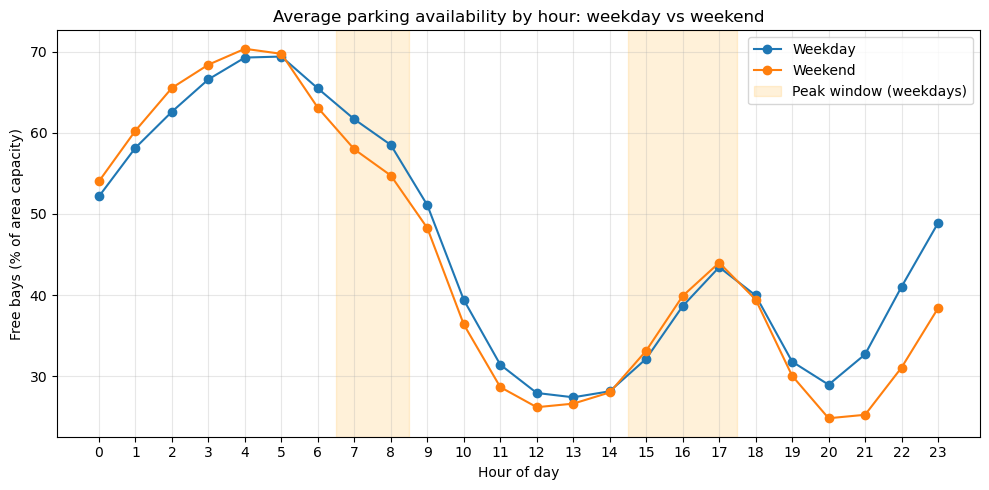

In [19]:
import matplotlib.pyplot as plt

# Spark aggregates to 48 rows (2 day types x 24 hours); Pandas is only used for plotting
hourly_pdf = (
    features_df
    .withColumn("day_type", F.when(F.col("day_of_week").between(2, 6), "Weekday").otherwise("Weekend"))
    .withColumn("free_rate", F.col("available_spots") / F.col("area_capacity"))
    .groupBy("day_type", "hour")
    .agg(F.avg("free_rate").alias("avg_free_rate"))
    .orderBy("day_type", "hour")
    .toPandas()
)

fig, ax = plt.subplots(figsize=(10, 5))
for day_type, grp in hourly_pdf.groupby("day_type"):
    ax.plot(grp["hour"], grp["avg_free_rate"] * 100, marker="o", label=day_type)

# Shade the weekday Peak windows defined in 1.2.3
ax.axvspan(6.5, 8.5, color="orange", alpha=0.15, label="Peak window (weekdays)")
ax.axvspan(14.5, 17.5, color="orange", alpha=0.15)

ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Free bays (% of area capacity)")
ax.set_title("Average parking availability by hour: weekday vs weekend")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Plot 1 – Hourly availability, weekday vs weekend.** Free bays peak at about 70% around 04:00–05:00, fall steeply from 08:00 to a minimum of about 27% at 12:00–13:00, partly recover to about 44% at 17:00 as workers leave, then dip again at 20:00 (29% on weekdays, 25% on weekends) before recovering overnight. Weekends are fuller in the evening (up to 10 points lower at 20:00–23:00), reflecting dining and entertainment demand. The shaded traffic Peak windows do not coincide with scarcity: the morning peak still has about 60% free bays because cars on the motorway have not yet parked, and the evening peak is a local maximum. The curve is strongly non-linear, so `hour` must be a feature and tree-based models, which split it into ranges, are more suitable than a linear model. `day_of_week` is also needed because the evening pattern differs by day type.

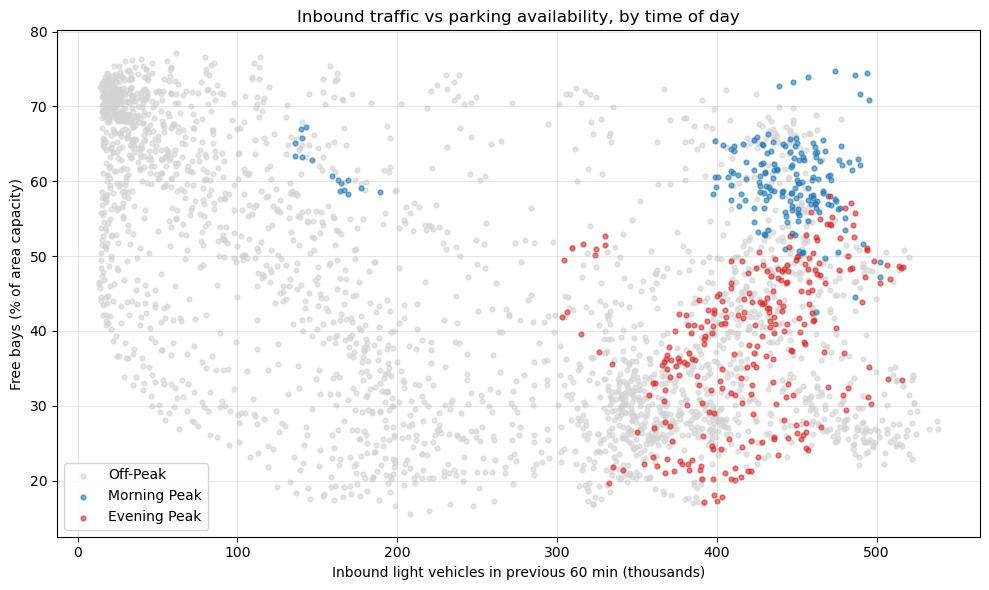

+------------+-------------------------+
|  time_group|corr_inbound_vs_free_rate|
+------------+-------------------------+
|Evening Peak|                    0.165|
|Morning Peak|                   -0.035|
|    Off-Peak|                   -0.352|
+------------+-------------------------+



In [20]:
# One point per 15-min snapshot: city-wide traffic vs average free-bay share across areas
city_pdf = (
    features_df
    .filter(F.col("traffic_imputed") == 0)   # real traffic values only
    .withColumn("free_rate", F.col("available_spots") / F.col("area_capacity"))
    .withColumn("time_group",
                F.when((F.col("Peak_Period") == "Peak") & (F.col("hour") < 12), "Morning Peak")
                 .when(F.col("Peak_Period") == "Peak", "Evening Peak")
                 .otherwise("Off-Peak"))
    .groupBy("snap_ts", "time_group")
    .agg(F.first("inbound_60m").alias("inbound_60m"),
         F.avg("free_rate").alias("avg_free_rate"))
    .toPandas()
)

fig, ax = plt.subplots(figsize=(10, 6))
for group, color in [("Off-Peak", "lightgrey"), ("Morning Peak", "tab:blue"), ("Evening Peak", "tab:red")]:
    grp = city_pdf[city_pdf["time_group"] == group]
    ax.scatter(grp["inbound_60m"] / 1000, grp["avg_free_rate"] * 100,
               s=12, alpha=0.6, color=color, label=group)

ax.set_xlabel("Inbound light vehicles in previous 60 min (thousands)")
ax.set_ylabel("Free bays (% of area capacity)")
ax.set_title("Inbound traffic vs parking availability, by time of day")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Correlation for each time group (computed in Spark) to support the discussion
(features_df
    .filter(F.col("traffic_imputed") == 0)
    .withColumn("free_rate", F.col("available_spots") / F.col("area_capacity"))
    .withColumn("time_group",
                F.when((F.col("Peak_Period") == "Peak") & (F.col("hour") < 12), "Morning Peak")
                 .when(F.col("Peak_Period") == "Peak", "Evening Peak")
                 .otherwise("Off-Peak"))
    .groupBy("time_group")
    .agg(F.round(F.corr("inbound_60m", "free_rate"), 3).alias("corr_inbound_vs_free_rate"))
    .show())

**Plot 2 – Inbound traffic vs availability by time of day.** Each point is one 15-minute snapshot (city-wide traffic vs the average free-bay share across areas). Low traffic (night) coincides with high availability, but above roughly 300,000 inbound vehicles per hour availability ranges from 17% to 75%. The relationship depends on time of day: within Off-Peak the correlation is −0.35, during the Morning Peak it is almost zero (−0.04) because arriving cars have not parked yet, and during the Evening Peak it is positive (+0.17) because heavy traffic coincides with workers leaving the CBD. Traffic volume alone is therefore a weak and unstable linear predictor; its effect is an interaction with `hour` and `Peak_Period`. This supports keeping traffic as supporting features alongside time and area features, and using tree ensembles that can learn such interactions rather than a single global slope.

## Part 2. Feature extraction and ML training <a class="anchor" name="part-2"></a>
In this section, you must use PySpark DataFrame functions and ML packages for data preparation, model building, and evaluation. Other ML packages, such as scikit-learn, should not be used to process the data; however, it’s fine to use them to display the result or evaluate your model.  
### 2.1 Feature Selection & Justification (10%)
Review the columns across the joined datasets. In a markdown cell, provide a structured discussion (maximum 300 words):  
- Identify which specific columns represent noise or distractors for the target label and explain why they should be excluded.  
- Justify the predictive features you have selected for your feature vector.  
- Detail the transformations required (e.g., index encoding, one-hot encoding, vector scaling) before vector assembly.  
Write the PySpark DataFrame code to assemble your filtered feature set.  


In [21]:
# Load Part 1 output (run 1.1.1 first after a restart)
from pyspark.sql import functions as F
FEAT_PATH = "/home/student/A2/features_part1.parquet"
features_df = spark.read.parquet(FEAT_PATH)
features_df.printSchema()
print("Rows:", features_df.count())

root
 |-- areaid: integer (nullable = true)
 |-- hour: integer (nullable = true)
 |-- snap_ts: timestamp (nullable = true)
 |-- observed_bays: long (nullable = true)
 |-- inbound_30m: double (nullable = true)
 |-- inbound_60m: double (nullable = true)
 |-- available_spots: double (nullable = true)
 |-- traffic_imputed: integer (nullable = true)
 |-- heavy_share_30m: double (nullable = true)
 |-- avg_speed_30m: double (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- Peak_Period: string (nullable = true)
 |-- area_capacity: long (nullable = true)
 |-- traffic_pressure: double (nullable = true)
 |-- available_rate: double (nullable = true)

Rows: 106680


#### 2.1 Feature Selection

The label is `available_spots` (vacant bays per area per 15-min snapshot). Columns from all datasets were reviewed in three groups.

**Excluded – leakage.** `vehiclepresent`, `departuretime`, `d_year/d_month/d_day/d_hour/d_minute` (parts of the departure time, see 1.1.2) and `inviolation` describe how a parking session ends, which is unknown at prediction time; they were used only to build the label. `available_rate` is the label divided by capacity. `observed_bays` comes from the same snapshot as the label (available ≤ observed), so the static `area_capacity` replaces it.

**Excluded – noise/distractors.** Identifiers (`id`, `deviceid`, `bayid`, `streetmarker`) and bay-level location codes (`streetid`, `betweenstreet1id/2id`, `sideofstreet`, `sidename`) lose meaning once data is aggregated to area level and would only let trees memorise. `sign`/`signplateid` are bay-level restriction text whose nulls mean "no restriction" (1.2.2). `area.json` and `street.json` only map IDs to names, which add nothing beyond `areaid`, so they are not joined. Raw traffic columns (`site`, `heading`, `vehicle_class`, `speed_bin`, `volume`, `date`, `time_bin`) are not used directly; they were filtered and aggregated into the lagged features below. `snap_ts` is replaced by its calendar parts.

**Selected features.**
- *Location:* `areaid`, `area_capacity` – each area's baseline supply.
- *Calendar:* `hour`, `day_of_week`, `Peak_Period` – the strong daily cycle (emptiest 4–5h, fullest 12–13h) and weekday/weekend pattern found in 1.3.
- *Lagged traffic:* `inbound_30m`, `inbound_60m`, `heavy_share_30m`, `avg_speed_30m`, `traffic_pressure` – demand heading into the CBD before the snapshot; built from past bins only, so also available in the A2B stream.
- `traffic_imputed` – flags the 407 imputed rows.

**Transformations.** Non-ordinal categoricals (`areaid`, `day_of_week`, `Peak_Period`) → StringIndexer → OneHotEncoder. `hour` stays numeric (its order matters; trees split it into ranges). No scaling is needed: tree splits are invariant to monotonic rescaling.

In [22]:
# Assemble the filtered feature set
LABEL = "available_spots"
cat_cols = ["areaid", "day_of_week", "Peak_Period"]
num_cols = ["hour", "area_capacity", "inbound_30m", "inbound_60m",
            "heavy_share_30m", "avg_speed_30m", "traffic_pressure", "traffic_imputed"]

model_df = features_df.select(
    *[F.col(c).cast("string").alias(c) for c in cat_cols],   # categoricals as string
    *[F.col(c).cast("double").alias(c) for c in num_cols],   # numerics as double
    F.col(LABEL).cast("double").alias(LABEL)
)

# Sanity check: no nulls left
model_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in model_df.columns]).show(vertical=True)
model_df.show(5)

-RECORD 0---------------
 areaid           | 0   
 day_of_week      | 0   
 Peak_Period      | 0   
 hour             | 0   
 area_capacity    | 0   
 inbound_30m      | 0   
 inbound_60m      | 0   
 heavy_share_30m  | 0   
 avg_speed_30m    | 0   
 traffic_pressure | 0   
 traffic_imputed  | 0   
 available_spots  | 0   

+------+-----------+-----------+----+-------------+-----------+-----------+--------------------+-----------------+----------------+---------------+---------------+
|areaid|day_of_week|Peak_Period|hour|area_capacity|inbound_30m|inbound_60m|     heavy_share_30m|    avg_speed_30m|traffic_pressure|traffic_imputed|available_spots|
+------+-----------+-----------+----+-------------+-----------+-----------+--------------------+-----------------+----------------+---------------+---------------+
|    16|          4|   Off-Peak| 5.0|        601.0|    76192.0|   116587.0| 0.23886653185710185|97.18730187331906|          193.99|            0.0|          496.0|
|    27|          

### 2.2 Preparing Spark ML Pipelines (10%)  <a class="anchor" name="2.2"></a>

Construct the required data transformation stages using PySpark MLlib:  
- StringIndexer and OneHotEncoder for non-ordinal categorical features.  
- VectorAssembler to combine all numerical and encoded categorical columns into a single features vector.  
- Perform scaling and normalisation as appropriate.  
(Note: If you have already created those transformations, you can use them directly in the pipelines.)  
Define two ML Estimators configured for continuous label regression:  
- Pipeline 1: RandomForestRegressor  
- Pipeline 2: GBTRegressor (Gradient-Boosted Tree Regressor)  
Assemble each estimator with your feature transformation stages into two clean, end-to-end pipeline objects. Do not call .fit() or .transform() at this stage.  


In [23]:
# Transformation stages (shared by both pipelines)
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

idx_cols = [f"{c}_idx" for c in cat_cols]
ohe_cols = [f"{c}_ohe" for c in cat_cols]

# string -> index; "keep" = unseen category won't crash in A2B
indexer = StringIndexer(inputCols=cat_cols, outputCols=idx_cols, handleInvalid="keep")
# index -> one-hot vector
encoder = OneHotEncoder(inputCols=idx_cols, outputCols=ohe_cols, handleInvalid="keep")
# all inputs -> one "features" vector
assembler = VectorAssembler(inputCols=ohe_cols + num_cols, outputCol="features")

In [24]:
# Two regressors + two end-to-end pipelines (no fit yet)
from pyspark.ml.regression import RandomForestRegressor, GBTRegressor

rf = RandomForestRegressor(featuresCol="features", labelCol=LABEL,
                           numTrees=50, maxDepth=8, seed=2026)
gbt = GBTRegressor(featuresCol="features", labelCol=LABEL,
                   maxIter=50, maxDepth=5, stepSize=0.1, seed=2026)

rf_pipeline = Pipeline(stages=[indexer, encoder, assembler, rf])
gbt_pipeline = Pipeline(stages=[indexer, encoder, assembler, gbt])

for name, p in [("RF", rf_pipeline), ("GBT", gbt_pipeline)]:
    print(name, [type(s).__name__ for s in p.getStages()])

RF ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'RandomForestRegressor']
GBT ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'GBTRegressor']


**Design notes.**
- `areaid`, `day_of_week` and `Peak_Period` have no natural order, so they are StringIndexed and one-hot encoded; an integer index alone would imply a false ranking (e.g. area 6 > area 5). `handleInvalid="keep"` prevents an unseen category in the A2B stream from crashing the model.
- **Scaling is not applied.** Both estimators are tree ensembles that split on value thresholds, so any monotonic rescaling leaves every split, and therefore every prediction, unchanged. Scaling one-hot columns would also remove their 0/1 meaning. It would only add an extra stage at prediction time.
- Both pipelines share identical preprocessing stages, so differences in 2.3 come from the algorithm alone. Hyperparameters are moderate starting values (RF: 50 trees, depth 8; GBT: 50 iterations, depth 5, step 0.1), tuned in Part 3.

### 2.3 Model Training and Evaluation (15%)

2.3.1 Data Splitting: Split your consolidated dataset into training (70%) and testing (30%) subsets using seed=2026.

In [26]:
# 70/30 split as required
train_df, test_df = model_df.randomSplit([0.7, 0.3], seed=2026)
train_df = train_df.cache()   # reused by both models
test_df = test_df.cache()
print(f"Train: {train_df.count():,}  Test: {test_df.count():,}")

Train: 74,627  Test: 32,053


2.3.2 Metric Discussion: Discuss the evaluation metrics you will use to evaluate your regression models (e.g., Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), R^2, etc.). Explain why you chose those metrics over others.

### 2.3.2 Evaluation Metrics

- **RMSE (primary).** Squares errors before averaging, so large misses are penalised heavily. The label is right-skewed (mean ≈ 53, median ≈ 21, max 516): in large areas a miss of 100 bays matters far more to drivers than a miss of 2, so RMSE is the main criterion for choosing the model. It is in the same unit as the label (bays).
- **MAE (secondary).** The average absolute error in bays, easy to communicate ("on average we are off by N spots") and less dominated by the few very large areas. A large gap between RMSE and MAE indicates occasional big errors.
- **R².** The share of variance explained compared with always predicting the mean. A trivial mean predictor has RMSE ≈ label std (≈ 81) and R² ≈ 0, so we also report this baseline to show that the models add real value.

**Metrics not used.** MSE carries the same information as RMSE but in squared units (bays²), which is hard to interpret. MAPE divides by the true value and is undefined here because `available_spots` is often 0 (full areas). R² alone does not show the size of errors in bays, so it is only used alongside RMSE and MAE.

2.3.3 Pipeline Fitting & Comparison: Train both pipelines on the training split. Evaluate their performance on the unseen test split using RegressionEvaluator.  
Present a side-by-side comparison table of the evaluation metrics, analyse why one algorithm outperformed the other, and save the superior pipeline model to disk. (You will load this model in Assignment 2B).  
(Note: You may need to go through a few training loops or use more data to create a better-performing model.)

In [27]:
# Fit both pipelines on train, evaluate on test
import time
import pandas as pd
from pyspark.ml.evaluation import RegressionEvaluator

def evaluate(pred, name):
    row = {"model": name}
    for m in ["rmse", "mae", "r2"]:
        row[m] = RegressionEvaluator(labelCol=LABEL, predictionCol="prediction",
                                     metricName=m).evaluate(pred)
    return row

results, models = [], {}
for name, pipe in [("RandomForest", rf_pipeline), ("GBT", gbt_pipeline)]:
    t0 = time.time()
    models[name] = pipe.fit(train_df)                 # learn on train only
    row = evaluate(models[name].transform(test_df), name)
    row["train_sec"] = round(time.time() - t0, 1)
    results.append(row)
    print(f"{name} done in {row['train_sec']}s")

# Baseline: always predict the train mean
mean_y = train_df.agg(F.avg(LABEL)).first()[0]
base = evaluate(test_df.withColumn("prediction", F.lit(mean_y)), "Baseline (mean)")
base["train_sec"] = 0.0
results.append(base)

results_pd = pd.DataFrame(results).set_index("model").round(3)
results_pd

RandomForest done in 43.5s
GBT done in 37.2s


,rmse,mae,r2,train_sec
model,,,,
RandomForest,17.951,10.953,0.951,43.5
GBT,15.681,8.602,0.962,37.2
Baseline (mean),80.863,52.974,-0.000,0.0


In [28]:
# Top 10 features of each model
sample = models["RandomForest"].transform(test_df.limit(1))
attrs = sample.schema["features"].metadata["ml_attr"]["attrs"]
feat_names = {a["idx"]: a["name"] for grp in attrs.values() for a in grp}

for name, m in models.items():
    imp = m.stages[-1].featureImportances.toArray()   # last stage = the model
    top = sorted(enumerate(imp), key=lambda x: -x[1])[:10]
    print(f"\n{name} top 10:")
    for i, v in top:
        print(f"  {feat_names[i]:<30} {v:.3f}")


RandomForest top 10:
  area_capacity                  0.500
  areaid_ohe_16                  0.174
  traffic_pressure               0.120
  hour                           0.052
  areaid_ohe_35                  0.045
  inbound_60m                    0.020
  areaid_ohe_23                  0.020
  areaid_ohe_24                  0.013
  areaid_ohe_38                  0.013
  inbound_30m                    0.013

GBT top 10:
  area_capacity                  0.596
  hour                           0.149
  areaid_ohe_16                  0.073
  areaid_ohe_38                  0.023
  day_of_week_ohe_2              0.019
  areaid_ohe_35                  0.016
  day_of_week_ohe_3              0.014
  avg_speed_30m                  0.013
  areaid_ohe_24                  0.013
  areaid_ohe_23                  0.011


In [29]:
# Save the better model (lowest RMSE) and verify by reloading
from pyspark.ml import PipelineModel

best_name = results_pd.drop("Baseline (mean)")["rmse"].idxmin()
MODEL_PATH = "models/best_parking_model"
models[best_name].write().overwrite().save(MODEL_PATH)

reloaded = PipelineModel.load(MODEL_PATH)
chk = evaluate(reloaded.transform(test_df), "reloaded")
print(f"Best: {best_name} | saved to {MODEL_PATH} | reload RMSE = {chk['rmse']:.3f}")

Best: GBT | saved to models/best_parking_model | reload RMSE = 15.681


### 2.3.3 Analysis

| Model | RMSE | MAE | R² | Train time |
|---|---|---|---|---|
| Random Forest | 17.95 | 10.95 | 0.951 | 44 s |
| **GBT** | **15.68** | **8.60** | **0.962** | 37 s |
| Baseline (train mean) | 80.86 | 52.97 | 0.000 | – |

**Result.** Both models reduce RMSE by about 80% compared with the mean baseline, so the features carry real signal. GBT is better on every metric: RMSE is 12.6% lower and MAE 21% lower than Random Forest, with a similar training time in this run (timings vary between runs with machine load).

**Why GBT won.** Availability is driven by interactions (area size × hour × day type). Random Forest averages 50 independent depth-8 trees, each grown on a bootstrap sample with a random subset of features; averaging reduces variance but not bias, so systematic errors common to all trees remain. GBT builds trees sequentially, each one fitted to the residuals of the previous ones, so it keeps correcting systematic errors such as a large area at a specific hour, which lowers bias. The larger gain in MAE than in RMSE shows that GBT mainly improves typical predictions.

**Feature importances.** Both models rely most on `area_capacity` (0.50 RF, 0.60 GBT), which sets the scale of each area. GBT gives `hour` far more weight (0.149 vs 0.052), matching the strong daily cycle in 1.3.2, whereas Random Forest spreads weight over `traffic_pressure` (0.12), which partly acts as another area-size proxy. Raw traffic features rank low in both, consistent with the weak correlations in 1.3.2, since all areas share the same city-wide traffic signal.

**Limitations.** RMSE is about 1.8× MAE, so some large errors remain, most likely in the biggest areas (e.g. area 16, 601 bays). The random split places neighbouring 15-minute snapshots in both train and test, so the scores are somewhat optimistic; a time-based split would be stricter.

The GBT PipelineModel is saved to `models/best_parking_model` (reload check: identical RMSE) and is tuned further in Part 3.

### Part 3: Performance Tuning (35%) <a class="anchor" name="part-3"></a>  
Apply the techniques you have learnt from the labs, for example, CrossValidator, TrainValidationSplit, ParamGridBuilder, etc., to perform further hyperparameter tuning and model optimisation.  
The assessment is based on the quality of your work/process, not the quality of your model. Please include your thoughts/ideas/discussions.

### Tuning plan

- **Model.** GBT, the better pipeline in 2.3.3 (test RMSE 15.68 vs 17.95 for Random Forest). The same preprocessing stages are reused, so only the model's hyperparameters change.
- **Hyperparameters.** `maxDepth` ∈ {5, 7} controls how many feature interactions a single tree can capture (e.g. area × hour × day type), which the importances in 2.3.3 suggest matter most. `maxIter` ∈ {50, 100} controls the number of boosting rounds, i.e. how far the model keeps correcting its residuals. The Part 2 setting (5, 50) is included in the grid, so the search is compared against it on equal terms. `stepSize` stays at 0.1: a smaller step would need more rounds and multiply the cost.
- **Validation.** 3-fold CrossValidator on the training split only; the test split stays unseen until the final comparison. Cross-validation uses every training row for validation once and gives a spread across folds, which TrainValidationSplit (a single split) cannot. k = 3 instead of 5 keeps the cost manageable.
- **Cost estimate.** 4 combinations × 3 folds + 1 refit on the full training split = 13 GBT fits. One GBT fit took about 40 seconds in Part 2, but deeper trees (depth 7) and more rounds (100) cost more, so roughly 10–20 minutes are expected; `parallelism=2` trains two models at a time.
- **Metric.** RMSE, the primary metric from 2.3.2.

Using the superior model pipeline identified in Part 2, perform systematic hyperparameter tuning to optimise predictive accuracy.  
1. Search Grid & Cross-Validation: Construct a parameter grid, and select at least two hyperparameters to tune (e.g., maxDepth, numTrees/maxIter, or stepSize/minInstancesPerNode).


In [30]:
# 1. Parameter grid for the winning model (GBT)
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

param_grid = (
    ParamGridBuilder()
    .addGrid(gbt.maxDepth, [5, 7])     # tree complexity
    .addGrid(gbt.maxIter, [50, 100])   # boosting rounds
    .build()
)

print(f"Grid size: {len(param_grid)} combinations")
for p in param_grid:
    print({k.name: v for k, v in p.items()})

Grid size: 4 combinations
{'maxDepth': 5, 'maxIter': 50}
{'maxDepth': 5, 'maxIter': 100}
{'maxDepth': 7, 'maxIter': 50}
{'maxDepth': 7, 'maxIter': 100}


2. Configure a CrossValidator with either k-fold cross-validation or TrainValidationSplit, using the metrics you suggested as the primary optimisation metric.


In [31]:
# 2. 3-fold cross-validation on the training split, optimising RMSE
sc.setJobDescription(f"A2A-3-CrossValidation-{student_auth_code}")

K = 3
rmse_eval = RegressionEvaluator(labelCol=LABEL, predictionCol="prediction", metricName="rmse")

cv = CrossValidator(estimator=gbt_pipeline, estimatorParamMaps=param_grid,
                    evaluator=rmse_eval, numFolds=K, parallelism=2, seed=2026)

t0 = time.time()
cv_model = cv.fit(train_df)          # test_df is NOT used here
cv_sec = time.time() - t0
print(f"Models trained: {len(param_grid)} x {K} folds + 1 refit = {len(param_grid) * K + 1}")
print(f"Cross-validation time: {cv_sec / 60:.1f} min")

# Average and spread of validation RMSE across folds
cv_pd = pd.DataFrame([
    {**{k.name: v for k, v in p.items()}, "avg_rmse": a, "std_rmse": s}
    for p, a, s in zip(param_grid, cv_model.avgMetrics, cv_model.stdMetrics)
]).sort_values("avg_rmse").round(3)
cv_pd

Models trained: 4 x 3 folds + 1 refit = 13
Cross-validation time: 21.6 min


,maxDepth,maxIter,avg_rmse,std_rmse
3,7,100,13.416,0.132
2,7,50,14.190,0.100
1,5,100,14.849,0.076
0,5,50,16.014,0.016


In [32]:
# Test-set comparison: tuned GBT vs Part 2 models
best_model = cv_model.bestModel                 # PipelineModel refit on full train
best_gbt = best_model.stages[-1]
print("Best params:", {"maxDepth": best_gbt.getMaxDepth(), "maxIter": best_gbt.getMaxIter()})

tuned = evaluate(best_model.transform(test_df), "GBT tuned (CV)")
tuned["train_sec"] = round(cv_sec, 1)           # total tuning time
compare_pd = pd.concat([results_pd, pd.DataFrame([tuned]).set_index("model").round(3)])

base_rmse = results_pd.loc["GBT", "rmse"]
print(f"Test RMSE: Part 2 GBT {base_rmse:.3f} -> tuned {tuned['rmse']:.3f} "
      f"({(base_rmse - tuned['rmse']) / base_rmse * 100:.1f}% lower)")
compare_pd

Best params: {'maxDepth': 7, 'maxIter': 100}
Test RMSE: Part 2 GBT 15.681 -> tuned 12.463 (20.5% lower)


,rmse,mae,r2,train_sec
model,,,,
RandomForest,17.951,10.953,0.951,43.5
GBT,15.681,8.602,0.962,37.2
Baseline (mean),80.863,52.974,-0.000,0.0
GBT tuned (CV),12.463,6.664,0.976,1295.8


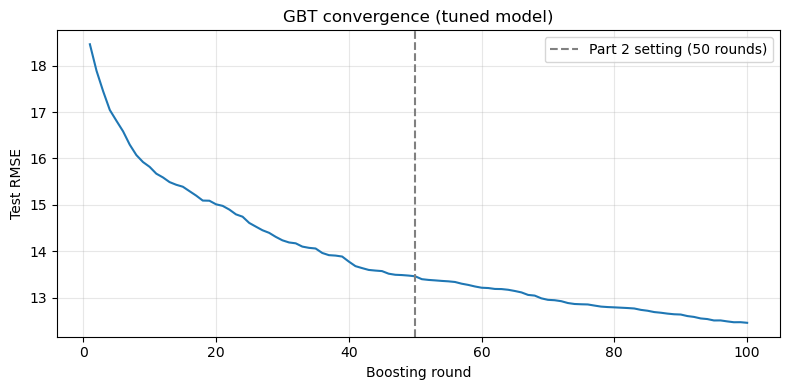

Round  10: RMSE 15.820
Round  25: RMSE 14.613
Round  50: RMSE 13.464
Round  75: RMSE 12.862
Round 100: RMSE 12.463


In [33]:
# Convergence: test RMSE after each boosting round of the tuned model
import matplotlib.pyplot as plt

best_gbt = best_model.stages[-1]                             # tuned GBT stage
prep = PipelineModel(best_model.stages[:-1])                 # preprocessing only
test_feat = prep.transform(test_df)
loss = best_gbt.evaluateEachIteration(test_feat, "squared")  # MSE per round
rmse_curve = [x ** 0.5 for x in loss]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(rmse_curve) + 1), rmse_curve)
ax.axvline(50, color="grey", linestyle="--", label="Part 2 setting (50 rounds)")
ax.set_xlabel("Boosting round")
ax.set_ylabel("Test RMSE")
ax.set_title("GBT convergence (tuned model)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

for i in [10, 25, 50, 75, 100]:
    if i <= len(rmse_curve):
        print(f"Round {i:>3}: RMSE {rmse_curve[i - 1]:.3f}")

3. Process Documentation & Analysis:
In a markdown cell, document:  
- The parameters and value ranges tested in your grid.  
- The computational cost and observed convergence behaviour across folds.  
- The quantitative performance gain achieved relative to your baseline model from Part 2.  

### 3 Process documentation & analysis

**Grid tested.** Tuning used a 3-fold `CrossValidator` on the training split only (74,627 rows), with RMSE as the evaluator. The test set was not touched until the final comparison. Two GBT parameters were tuned: `maxDepth` ∈ {5, 7} and `maxIter` ∈ {50, 100}. `stepSize` was kept at 0.1 and `seed` at 2026. The grid includes the Part 2 setting (depth 5, 50 rounds), so the baseline is compared under the same CV procedure. These two parameters were chosen because they control model capacity: deeper trees capture interactions (for example area × hour), and more rounds let boosting correct remaining errors.

| maxDepth | maxIter | CV avg RMSE | CV std |
|---|---|---|---|
| 5 | 50 (Part 2) | 16.014 | 0.016 |
| 5 | 100 | 14.849 | 0.076 |
| 7 | 50 | 14.190 | 0.100 |
| **7** | **100** | **13.416** | 0.132 |

**Computational cost.** 4 combinations × 3 folds = 12 fits, plus 1 refit of the best setting on the full training split, gives 13 fits. With `parallelism=2`, the whole search took **21.6 minutes (1,296 s)**, compared with about **37 s** for a single Part 2 GBT. Most of the cost comes from the depth-7 / 100-round fits. Tuning is a one-off offline step, so this cost is acceptable.

**Behaviour across folds.** Results were stable across folds: the standard deviation of RMSE is between 0.016 and 0.132, so the ranking of the four settings is the same on every fold. Both parameters help on their own. Going from depth 5 to 7 lowers CV RMSE by about 1.4–1.8, and going from 50 to 100 rounds lowers it by about 0.8–1.2. The gap between the best setting and the Part 2 setting (2.6) is about 20 times larger than the fold standard deviation, so the gain is not caused by a lucky split.

**Convergence of the tuned model.** The curve above shows test RMSE after each boosting round. It is used only to describe the model, not to choose parameters, because selection was already done by CV. RMSE falls steeply in the first 20 rounds and then decreases slowly: 15.82 (round 10) → 13.46 (round 50) → 12.86 (round 75) → 12.46 (round 100). At round 50 the tuned model is already well below Part 2 (15.68), so most of the gain comes from deeper trees, and the extra 50 rounds add another 1.0. The curve never turns upward, so there is no sign of overfitting. It is still slightly decreasing at round 100.

**Performance gain vs Part 2 baseline (same test set, 32,053 rows).**

| Metric | Part 2 GBT (5, 50) | Tuned GBT (7, 100) | Change |
|---|---|---|---|
| RMSE | 15.681 | **12.463** | −20.5% |
| MAE | 8.602 | **6.664** | −22.5% |
| R² | 0.962 | **0.976** | +0.014 |

The tuned model's average error drops from about 8.6 to about 6.7 spots per area. It is also 84.6% better than the mean baseline (RMSE 80.86). Test RMSE (12.46) is slightly lower than the CV estimate (13.42), and the same happens for the Part 2 setting (15.68 vs 16.01). This is expected: each CV fold trains on only two-thirds of the training data, while the final model is refitted on all of it. So the CV estimate is reliable, and the model does not overfit.

**Discussion & next steps.** The best setting lies at the edge of the grid (largest depth and largest number of rounds), and the convergence curve has not fully flattened. This suggests that a little more improvement is possible. A next round could test `maxDepth` ∈ {7, 9} and `maxIter` ∈ {100, 150}, or use a lower `stepSize` with more rounds. A `TrainValidationSplit` could be used to keep the cost down. A lag feature, such as available spots in the previous snapshot, is likely to help more than further tuning, and is left as future work. The tuned model is larger than the Part 2 one, but A2B only needs to score 37 areas every 15 minutes, so the extra prediction cost is small. The tuned pipeline is therefore exported for A2B.

4. Model Export: Save your finalised, tuned pipeline model to an export directory (e.g., models/best_tuned_parking_model).  
This persisted model will be directly deployed into your real-time Kafka streaming consumer in Assignment 2B.  
(note: If you don't complete the optimisation part, you can also use the model from part 2 in A2B.)

In [34]:
# 4. Export the tuned pipeline for the A2B Kafka consumer
TUNED_PATH = "models/best_tuned_parking_model"
best_model.write().overwrite().save(TUNED_PATH)

reloaded_tuned = PipelineModel.load(TUNED_PATH)
chk = evaluate(reloaded_tuned.transform(test_df), "reloaded")
print(f"Saved to {TUNED_PATH} | reload RMSE = {chk['rmse']:.3f}")

Saved to models/best_tuned_parking_model | reload RMSE = 12.463


## References:
Please add your references below:

1. Apache Spark. (n.d.). *ML Pipelines*. Spark documentation. https://spark.apache.org/docs/latest/ml-pipeline.html
2. Apache Spark. (n.d.). *Extracting, transforming and selecting features* (StringIndexer, OneHotEncoder, VectorAssembler, Imputer). Spark documentation. https://spark.apache.org/docs/latest/ml-features.html
3. Apache Spark. (n.d.). *Classification and regression* (random forest and gradient-boosted tree regression). Spark documentation. https://spark.apache.org/docs/latest/ml-classification-regression.html
4. Apache Spark. (n.d.). *ML Tuning: model selection and hyperparameter tuning* (CrossValidator, ParamGridBuilder). Spark documentation. https://spark.apache.org/docs/latest/ml-tuning.html
5. Apache Spark. (n.d.). *PySpark API reference* (`pyspark.sql.functions`, `Window`). https://spark.apache.org/docs/latest/api/python/
6. Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
7. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.
8. Monash University. (2026). *FIT5202 Data Processing for Big Data*: lecture and lab materials, and the Assignment 2A dataset and specification.

#### Generative AI declaration

I used Claude (Anthropic) as a study and writing assistant during this assignment. It was used to:
- explain Spark concepts and the reasoning behind design choices (for example window functions, the label definition, CrossValidator);
- suggest and debug PySpark code, which I then ran, checked against the outputs and adapted myself;
- draft and edit the English wording of the markdown explanations, which I revised to match my own results.

All analysis decisions, code execution and final results in this notebook were checked by me, and I take responsibility for the submitted work.